![logo](images/untumbes.PNG)

<b><center>Prof. Dr. Jorge Zavaleta - zavaleta.jorge@gmail.com </center></b>

# Preparación de datos

> La **fase de preparación de datos** cubre todas las actividades necesarias para
construir el conjunto de datos final a partir de los datos iniciales sin procesar.
> Es probable que las tareas de preparación de datos se realicen varias veces y no en ningún orden prescrito.
> Las tareas incluyen selección de tablas, registros y atributos, así como
transformación y limpieza de datos para herramientas de modelado.
> La preparación de datos es un paso crucial en el proceso de minería de datos y, a menudo, consume más tiempo que las propias técnicas de minería.

## Importación de las bibliotecas

In [1]:
# librarys
import numpy as np                          # calculo cientifico
import pandas as pd                         # manejo de dataframes
import matplotlib.pyplot as plt             # visualizacion grafica
import seaborn as sns                       # visualizacion grafica

## Lectura del dataset

In [2]:
# paths
path_dataset ='data/'    # diretorio do dataset local
# dataset read
file_name='covid_19.csv'          # nome do dataset
dataset1 = pd.read_csv(path_dataset+file_name,sep=';',encoding='utf-8',low_memory=False) #index_col=0  #encoding='ISO-8859-1','latin-1')     # leitura do dataset
dataset1.head()

,DT_NOTIFIC,SEM_NOT,DT_SIN_PRI,SEM_PRI,SG_UF_NOT,ID_REGIONA,CO_REGIONA,ID_MUNICIP,CO_MUN_NOT,ID_UNIDADE,...,LOTE_2_COV,LOTE_REF,FNT_IN_COV,DOSE_2REF,FAB_COVRF2,LOTE_REF2,TRAT_COV,TIPO_TRAT,OUT_TRAT,DT_TRT_COV
0,18/01/2023,3,17/01/2023,3,MG,LEOPOLDINA,1453.0,ALEM PARAIBA,310150,HOSPITAL SAO SALVADOR,...,202010031,28235BD,2,11/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,NaN,NaN,NaN,NaN
1,04/01/2023,1,01/01/2023,1,RJ,NaN,NaN,VOLTA REDONDA,330630,SECRETARIA MUNICIPAL DE SAUDE DE VOLTA REDONDA,...,NaN,NaN,2,10/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FP7082,2.0,NaN,NaN,NaN
2,08/01/2023,2,05/01/2023,1,SP,GVE XV BAURU,1340.0,JAU,352530,SANTA CASA DE JAU,...,210137,FH8023,2,19/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,2.0,NaN,NaN,NaN
3,23/01/2023,4,18/01/2023,3,SP,GVE XIX MARILIA,1344.0,ADAMANTINA,350010,SANTA CASA DE MIS DE ADAMANTINA NA PROVIDENCIA...,...,216VCD216Z,FK8917,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN
4,05/02/2023,6,03/02/2023,5,SP,GVE XVII CAMPINAS,1342.0,CAMPINAS,350950,UNIDADE DE PRONTO ATENDIMENTO ANCHIETA METROPO...,...,210144,FH8026,2,25/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FM2948,2.0,NaN,NaN,NaN


## Visualizar el diccionario de datos

[Diccionario de datos](pdf/Dicionario_dados_19_09_2022.pdf)

## Verificar las dimensiones

In [3]:
# dimension
dataset1.shape

(226763, 173)

## Copia del dataset original

In [4]:
# fazendo uma copia do dataframe
work_data = dataset1.copy()

In [5]:
# work data
work_data.head()

,DT_NOTIFIC,SEM_NOT,DT_SIN_PRI,SEM_PRI,SG_UF_NOT,ID_REGIONA,CO_REGIONA,ID_MUNICIP,CO_MUN_NOT,ID_UNIDADE,...,LOTE_2_COV,LOTE_REF,FNT_IN_COV,DOSE_2REF,FAB_COVRF2,LOTE_REF2,TRAT_COV,TIPO_TRAT,OUT_TRAT,DT_TRT_COV
0,18/01/2023,3,17/01/2023,3,MG,LEOPOLDINA,1453.0,ALEM PARAIBA,310150,HOSPITAL SAO SALVADOR,...,202010031,28235BD,2,11/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,NaN,NaN,NaN,NaN
1,04/01/2023,1,01/01/2023,1,RJ,NaN,NaN,VOLTA REDONDA,330630,SECRETARIA MUNICIPAL DE SAUDE DE VOLTA REDONDA,...,NaN,NaN,2,10/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FP7082,2.0,NaN,NaN,NaN
2,08/01/2023,2,05/01/2023,1,SP,GVE XV BAURU,1340.0,JAU,352530,SANTA CASA DE JAU,...,210137,FH8023,2,19/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,2.0,NaN,NaN,NaN
3,23/01/2023,4,18/01/2023,3,SP,GVE XIX MARILIA,1344.0,ADAMANTINA,350010,SANTA CASA DE MIS DE ADAMANTINA NA PROVIDENCIA...,...,216VCD216Z,FK8917,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN
4,05/02/2023,6,03/02/2023,5,SP,GVE XVII CAMPINAS,1342.0,CAMPINAS,350950,UNIDADE DE PRONTO ATENDIMENTO ANCHIETA METROPO...,...,210144,FH8026,2,25/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FM2948,2.0,NaN,NaN,NaN


## Visualizar Datos faltantes

In [6]:
# visualizando dados faltantes, os 30 maiores
md = work_data.isna().sum().sort_values(ascending=False)[:30]
md

DT_TRT_COV    226763
DT_RT_VGM     226763
SURTO_SG      226763
CO_PS_VGM     226763
LO_PS_VGM     226763
DT_VGM        226763
PAIS_VGM      226763
FLUBLI_OUT    226755
AN_PARA2      226753
AN_PARA1      226731
AN_PARA3      226731
AN_ADENO      226721
FLUASU_OUT    226721
PCR_PARA4     226694
PCR_PARA2     226658
DT_2_DOSE     226578
PCR_PARA1     226535
DT_1_DOSE     226522
DS_AN_OUT     226518
DT_DOSEUNI    226505
AN_OUTRO      226495
OUT_TRAT      226354
DT_VAC_MAE    226274
OBES_IMC      226265
OUT_SOR       226177
OUT_ANTIV     226139
TIPO_TRAT     226052
OUT_ANIM      226032
PCR_BOCA      225861
PCR_PARA3     225541
dtype: int64

## Algunos gráficos

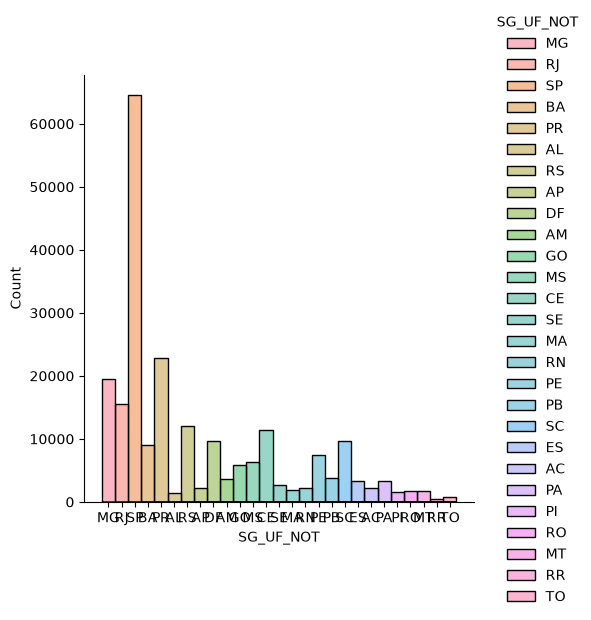

In [7]:
# work data
fig_bar = sns.displot(data = work_data, x='SG_UF_NOT',hue='SG_UF_NOT')
plt.show(fig_bar)

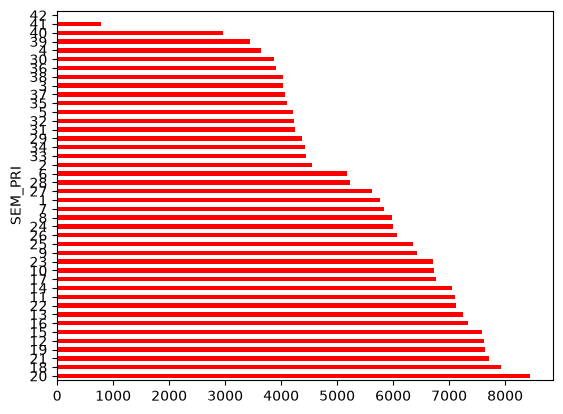

In [8]:
# Tipos de testes no dataframe consultas
work_data.SEM_PRI.value_counts().plot(kind='barh', color='r');

## Operando con valores nulos

- **isnull()**: Genera una máscara booleana que indica los valores faltantes
- **notnull()**: Lo contrario de **isnull()**
- **dropna()**: Devuelve una versión filtrada de los datos
- **fillna()**: Devuelve una copia de los datos con valores faltantes completados o imputados

### Detectando valores null

Las estructuras de datos de **Pandas** tienen dos métodos útiles para detectar datos nulos: **isnull()** y **notnull()**. Cualquiera de los dos devolverá una máscara booleana sobre los datos.

In [9]:
# exemplo
data = pd.Series([1, np.nan, 'hello', None])

In [10]:
data

0        1
1      NaN
2    hello
3     None
dtype: object

In [11]:
# isnull
data.isnull()

0    False
1     True
2    False
3     True
dtype: bool

In [12]:
# work_data
work_data.isnull()

,DT_NOTIFIC,SEM_NOT,DT_SIN_PRI,SEM_PRI,SG_UF_NOT,ID_REGIONA,CO_REGIONA,ID_MUNICIP,CO_MUN_NOT,ID_UNIDADE,...,LOTE_2_COV,LOTE_REF,FNT_IN_COV,DOSE_2REF,FAB_COVRF2,LOTE_REF2,TRAT_COV,TIPO_TRAT,OUT_TRAT,DT_TRT_COV
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,True,True,True
1,False,False,False,False,False,True,True,False,False,False,...,True,True,False,False,False,False,False,True,True,True
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,True
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,True,True,False,True,True,True
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226758,False,False,False,False,False,False,False,False,False,False,...,True,True,False,True,True,True,True,True,True,True
226759,False,False,False,False,False,False,False,False,False,False,...,True,True,False,True,True,True,False,True,True,True
226760,False,False,False,False,False,False,False,False,False,False,...,True,True,False,True,True,True,False,True,True,True
226761,False,False,False,False,False,True,True,False,False,False,...,True,True,False,True,True,True,False,True,True,True


In [13]:
#
data[data.isnull()]

1     NaN
3    None
dtype: object

### Eliminando valores nulos

Existen los métodos convenientes, **dropna()** (que elimina los valores de NA) y **fillna()** (que completa los valores de NA).

In [14]:
# dropna()
data.dropna()

0        1
2    hello
dtype: object

In [15]:
# exemplo
df = pd.DataFrame([[1,      np.nan, 2],
                   [2,      3,      5],
                   [np.nan, 4,      6]])
df.head()

,0,1,2
0,1.0,NaN,2
1,2.0,3.0,5
2,NaN,4.0,6


In [16]:
# drop
df.dropna()

,0,1,2
1,2.0,3.0,5


In [17]:
# work_data
wd = work_data.dropna()
wd.head()

,DT_NOTIFIC,SEM_NOT,DT_SIN_PRI,SEM_PRI,SG_UF_NOT,ID_REGIONA,CO_REGIONA,ID_MUNICIP,CO_MUN_NOT,ID_UNIDADE,...,LOTE_2_COV,LOTE_REF,FNT_IN_COV,DOSE_2REF,FAB_COVRF2,LOTE_REF2,TRAT_COV,TIPO_TRAT,OUT_TRAT,DT_TRT_COV


In [18]:
wd.shape

(0, 173)

In [19]:
# work_data
work_data.head(7)

,DT_NOTIFIC,SEM_NOT,DT_SIN_PRI,SEM_PRI,SG_UF_NOT,ID_REGIONA,CO_REGIONA,ID_MUNICIP,CO_MUN_NOT,ID_UNIDADE,...,LOTE_2_COV,LOTE_REF,FNT_IN_COV,DOSE_2REF,FAB_COVRF2,LOTE_REF2,TRAT_COV,TIPO_TRAT,OUT_TRAT,DT_TRT_COV
0,18/01/2023,3,17/01/2023,3,MG,LEOPOLDINA,1453.0,ALEM PARAIBA,310150,HOSPITAL SAO SALVADOR,...,202010031,28235BD,2,11/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,NaN,NaN,NaN,NaN
1,04/01/2023,1,01/01/2023,1,RJ,NaN,NaN,VOLTA REDONDA,330630,SECRETARIA MUNICIPAL DE SAUDE DE VOLTA REDONDA,...,NaN,NaN,2,10/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FP7082,2.0,NaN,NaN,NaN
2,08/01/2023,2,05/01/2023,1,SP,GVE XV BAURU,1340.0,JAU,352530,SANTA CASA DE JAU,...,210137,FH8023,2,19/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,2.0,NaN,NaN,NaN
3,23/01/2023,4,18/01/2023,3,SP,GVE XIX MARILIA,1344.0,ADAMANTINA,350010,SANTA CASA DE MIS DE ADAMANTINA NA PROVIDENCIA...,...,216VCD216Z,FK8917,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN
4,05/02/2023,6,03/02/2023,5,SP,GVE XVII CAMPINAS,1342.0,CAMPINAS,350950,UNIDADE DE PRONTO ATENDIMENTO ANCHIETA METROPO...,...,210144,FH8026,2,25/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FM2948,2.0,NaN,NaN,NaN
5,06/02/2023,6,02/02/2023,5,RJ,NaN,NaN,NITEROI,330330,HOSPITAL GETULIO VARGAS FILHO,...,NaN,NaN,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN
6,04/02/2023,5,25/01/2023,4,BA,NUCLEO REGIONAL DE SAUDE LESTE,1380.0,SALVADOR,292740,HOSPITAL GERAL ROBERTO SANTOS,...,NaN,NaN,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN


> Alternativamente, puede colocar los valores NA a lo largo de un eje diferente; axis=1 elimina todas las columnas que contienen un valor nulo

In [20]:
df.dropna(axis='columns')

,2
0,2
1,5
2,6


In [21]:
wdc = work_data.dropna(axis='columns')
wdc.head()

,DT_NOTIFIC,SEM_NOT,DT_SIN_PRI,SEM_PRI,SG_UF_NOT,ID_MUNICIP,CO_MUN_NOT,ID_UNIDADE,CO_UNI_NOT,CS_SEXO,...,TP_IDADE,COD_IDADE,CS_GESTANT,CS_RACA,ID_PAIS,CO_PAIS,FATOR_RISC,DT_DIGITA,HISTO_VGM,FNT_IN_COV
0,18/01/2023,3,17/01/2023,3,MG,ALEM PARAIBA,310150,HOSPITAL SAO SALVADOR,2122677,M,...,3,3075,6,9,BRASIL,1,1,20/01/2023,0,2
1,04/01/2023,1,01/01/2023,1,RJ,VOLTA REDONDA,330630,SECRETARIA MUNICIPAL DE SAUDE DE VOLTA REDONDA,6086381,M,...,3,3067,6,1,BRASIL,1,1,23/01/2023,0,2
2,08/01/2023,2,05/01/2023,1,SP,JAU,352530,SANTA CASA DE JAU,2791722,F,...,3,3072,5,1,BRASIL,1,1,25/01/2023,0,2
3,23/01/2023,4,18/01/2023,3,SP,ADAMANTINA,350010,SANTA CASA DE MIS DE ADAMANTINA NA PROVIDENCIA...,2077647,F,...,3,3046,5,1,BRASIL,1,2,27/01/2023,0,2
4,05/02/2023,6,03/02/2023,5,SP,CAMPINAS,350950,UNIDADE DE PRONTO ATENDIMENTO ANCHIETA METROPO...,2022877,M,...,3,3071,6,1,BRASIL,1,2,06/02/2023,0,2


In [22]:
wdc.shape

(226763, 21)

In [23]:
df[3] = np.nan
df

,0,1,2,3
0,1.0,NaN,2,NaN
1,2.0,3.0,5,NaN
2,NaN,4.0,6,NaN


In [24]:
df.dropna(axis='columns', how='all')

,0,1,2
0,1.0,NaN,2
1,2.0,3.0,5
2,NaN,4.0,6


> Para un control más detallado, el parámetro **thresh** le permite especificar un número mínimo de valores no nulos para la fila/columna que se mantendrá:

In [25]:
df.dropna(axis='rows', thresh=3)

,0,1,2,3
1,2.0,3.0,5,NaN


### Llenando valores nulos
>A veces, en lugar de eliminar los valores de NA, es mejor reemplazarlos con un valor válido. Este valor podría ser un número único como cero, o podría ser algún tipo de imputación o interpolación de los buenos valores. Se podría hacer usando el método *isnull()* como máscara, pero debido a que es una operación tan común, **Pandas** proporciona el método **fillna()**, que devuelve una copia de la matriz con los valores nulos reemplazados.

In [26]:
data = pd.Series([1, np.nan, 2, None, 3], index=list('abcde'))
data

a    1.0
b    NaN
c    2.0
d    NaN
e    3.0
dtype: float64

In [27]:
data.fillna(0)

a    1.0
b    0.0
c    2.0
d    0.0
e    3.0
dtype: float64

In [28]:
# wdc
print(wdc[['SEM_NOT']].isnull().sum())

SEM_NOT    0
dtype: int64


### Función para encontrar porcentaje de valores nulos
Herramientas:
- Biblioteca Python Missingno (vesión desactualizada, solo funciona con Python version 3.7)

Instalación:

Terminal de comandos: `pip install missingno`

Anaconda: `conda search missingno --channel conda-forge`

Jupyter Notebook: `!pip install missingno`

- Dataprep: https://dataprep.ai/. Herramienta para preparación de datos, recopila, limpia y visualiza tus datos en Python con pocas líneas de código. (Solo funciona en Python versión 3.0 - 3.10)

In [ ]:
# function to calculate missing values by column
def missing_values_dataset(df):
        # Total missing values
        mis_val = df.isnull().sum()
        
        # Percentage of missing values
        mis_val_percent = 100 * df.isnull().sum() / len(df)
        
        # Make a table with the results
        mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)
        
        # Rename the columns
        mis_val_table_ren_columns = mis_val_table.rename(
        columns = {0 : 'Missing Values', 1 : '% of Total Values'})
        
        # Sort the table by percentage of missing descending
        mis_val_table_ren_columns = mis_val_table_ren_columns[
            mis_val_table_ren_columns.iloc[:,1] != 0].sort_values(
        '% of Total Values', ascending=False).round(1)
        
        # Print some summary information
        print ("Your selected dataframe has " + str(df.shape[1]) + " columns.\n"      
            "There are " + str(mis_val_table_ren_columns.shape[0]) +
              " columns that have missing values.")
        
        # Return the dataframe with missing information
        return mis_val_table_ren_columns

In [30]:
dm = missing_values_dataset(work_data)
dm

Your selected dataframe has 173 columns.
There are 152 columns that have missing values.


,Missing Values,% of Total Values
DT_TRT_COV,226763,100.0
SURTO_SG,226763,100.0
PAIS_VGM,226763,100.0
CO_PS_VGM,226763,100.0
LO_PS_VGM,226763,100.0
...,...,...
DT_NASC,71,0.0
VACINA_COV,56,0.0
ID_MN_RESI,54,0.0
SG_UF,54,0.0


In [31]:
work_data.head(7)

,DT_NOTIFIC,SEM_NOT,DT_SIN_PRI,SEM_PRI,SG_UF_NOT,ID_REGIONA,CO_REGIONA,ID_MUNICIP,CO_MUN_NOT,ID_UNIDADE,...,LOTE_2_COV,LOTE_REF,FNT_IN_COV,DOSE_2REF,FAB_COVRF2,LOTE_REF2,TRAT_COV,TIPO_TRAT,OUT_TRAT,DT_TRT_COV
0,18/01/2023,3,17/01/2023,3,MG,LEOPOLDINA,1453.0,ALEM PARAIBA,310150,HOSPITAL SAO SALVADOR,...,202010031,28235BD,2,11/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,NaN,NaN,NaN,NaN
1,04/01/2023,1,01/01/2023,1,RJ,NaN,NaN,VOLTA REDONDA,330630,SECRETARIA MUNICIPAL DE SAUDE DE VOLTA REDONDA,...,NaN,NaN,2,10/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FP7082,2.0,NaN,NaN,NaN
2,08/01/2023,2,05/01/2023,1,SP,GVE XV BAURU,1340.0,JAU,352530,SANTA CASA DE JAU,...,210137,FH8023,2,19/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,2.0,NaN,NaN,NaN
3,23/01/2023,4,18/01/2023,3,SP,GVE XIX MARILIA,1344.0,ADAMANTINA,350010,SANTA CASA DE MIS DE ADAMANTINA NA PROVIDENCIA...,...,216VCD216Z,FK8917,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN
4,05/02/2023,6,03/02/2023,5,SP,GVE XVII CAMPINAS,1342.0,CAMPINAS,350950,UNIDADE DE PRONTO ATENDIMENTO ANCHIETA METROPO...,...,210144,FH8026,2,25/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FM2948,2.0,NaN,NaN,NaN
5,06/02/2023,6,02/02/2023,5,RJ,NaN,NaN,NITEROI,330330,HOSPITAL GETULIO VARGAS FILHO,...,NaN,NaN,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN
6,04/02/2023,5,25/01/2023,4,BA,NUCLEO REGIONAL DE SAUDE LESTE,1380.0,SALVADOR,292740,HOSPITAL GERAL ROBERTO SANTOS,...,NaN,NaN,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN


In [32]:
# elimina colunas com dados faltantes usando drop
work_data.drop(['DT_VGM'], axis=1, inplace=True)
work_data.head()

,DT_NOTIFIC,SEM_NOT,DT_SIN_PRI,SEM_PRI,SG_UF_NOT,ID_REGIONA,CO_REGIONA,ID_MUNICIP,CO_MUN_NOT,ID_UNIDADE,...,LOTE_2_COV,LOTE_REF,FNT_IN_COV,DOSE_2REF,FAB_COVRF2,LOTE_REF2,TRAT_COV,TIPO_TRAT,OUT_TRAT,DT_TRT_COV
0,18/01/2023,3,17/01/2023,3,MG,LEOPOLDINA,1453.0,ALEM PARAIBA,310150,HOSPITAL SAO SALVADOR,...,202010031,28235BD,2,11/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,NaN,NaN,NaN,NaN
1,04/01/2023,1,01/01/2023,1,RJ,NaN,NaN,VOLTA REDONDA,330630,SECRETARIA MUNICIPAL DE SAUDE DE VOLTA REDONDA,...,NaN,NaN,2,10/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FP7082,2.0,NaN,NaN,NaN
2,08/01/2023,2,05/01/2023,1,SP,GVE XV BAURU,1340.0,JAU,352530,SANTA CASA DE JAU,...,210137,FH8023,2,19/04/2022,87 - COVID-19 PFIZER - COMIRNATY,FN9606,2.0,NaN,NaN,NaN
3,23/01/2023,4,18/01/2023,3,SP,GVE XIX MARILIA,1344.0,ADAMANTINA,350010,SANTA CASA DE MIS DE ADAMANTINA NA PROVIDENCIA...,...,216VCD216Z,FK8917,2,NaN,NaN,NaN,2.0,NaN,NaN,NaN
4,05/02/2023,6,03/02/2023,5,SP,GVE XVII CAMPINAS,1342.0,CAMPINAS,350950,UNIDADE DE PRONTO ATENDIMENTO ANCHIETA METROPO...,...,210144,FH8026,2,25/05/2022,87 - COVID-19 PFIZER - COMIRNATY,FM2948,2.0,NaN,NaN,NaN


## Ejercicios:

1. Eliminar todas las columnas com >70% de valores faltantes!!
2. Calcular las dimensiones del dataset final
3. Instalar el Missigno y el Dataprep
4. Visualzar los datos faltantes work_data usando missigno e dataprep

---

<center><b>© Jorge Zavaleta, Minería de Datos, 2026</b></center>